In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
from google.colab import drive
drive.mount('/content/drive')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
dataset = pd.read_csv(r'/content/drive/My Drive/AIML Assignment/salary_Data.csv')

print("First 5 rows of dataset:")
print(dataset.head())

print("\nDataset Information:")
print(dataset.info())

First 5 rows of dataset:
   YearsExperience   Salary
0              1.1  39343.0
1              1.3  46205.0
2              1.5  37731.0
3              2.0  43525.0
4              2.2  39891.0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes
None


Slope: 9345.942443122372
Intercept: 26816.192244031183

Training Results
MSE: 36852948.76438455
MAE: 5310.294905607347
R2 Score: 0.9381900012894278

Testing Results
MSE: 21026037.329511296
MAE: 3426.4269374307078
R2 Score: 0.9749154407708353


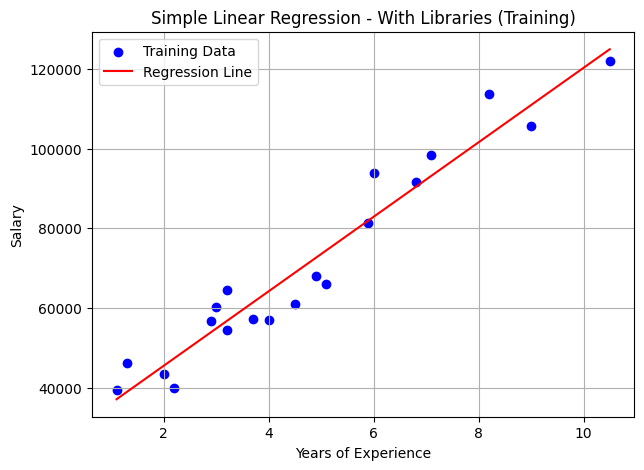

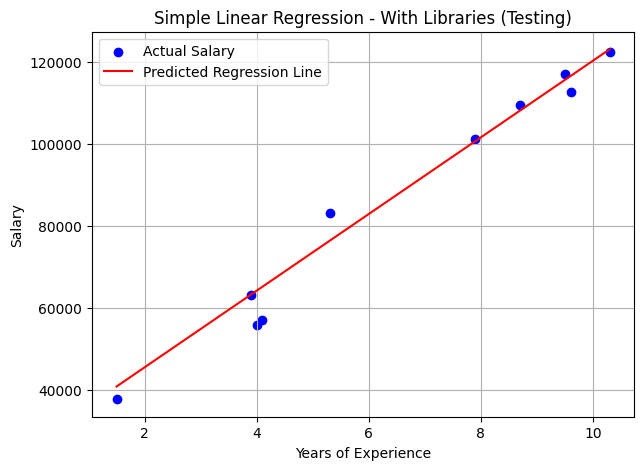

In [ ]:
x = dataset.iloc[:,:-1].values
y = dataset.iloc[:,1].values

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=1/3,
    random_state=0
)

regressor = LinearRegression()

regressor.fit(X_train, y_train)

y_train_pred = regressor.predict(X_train)
y_test_pred = regressor.predict(X_test)

print("Slope:", regressor.coef_[0])
print("Intercept:", regressor.intercept_)


print("\nTraining Results")
print("MSE:", mean_squared_error(y_train, y_train_pred))
print("MAE:", mean_absolute_error(y_train, y_train_pred))
print("R2 Score:", r2_score(y_train, y_train_pred))

print("\nTesting Results")
print("MSE:", mean_squared_error(y_test, y_test_pred))
print("MAE:", mean_absolute_error(y_test, y_test_pred))
print("R2 Score:", r2_score(y_test, y_test_pred))

plt.figure(figsize=(7, 5))
plt.scatter(X_train, y_train, color='blue', label='Training Data')

train_idx = X_train[:, 0].argsort()
plt.plot(
    X_train[train_idx],
    y_train_pred[train_idx],
    color='red',
    label='Regression Line'
)

plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Simple Linear Regression - With Libraries (Training)')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(X_test, y_test, color='blue', label='Actual Salary')

test_idx = X_test[:, 0].argsort()
plt.plot(
    X_test[test_idx],
    y_test_pred[test_idx],
    color='red',
    label='Predicted Regression Line'
)

plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Simple Linear Regression - With Libraries (Testing)')
plt.legend()
plt.grid(True)
plt.show()


========== Without Libraries ==========
Slope: 9345.942443122376
Intercept: 26816.19224403117

Training Results
MSE: 36852948.76438456
MAE: 5310.2949056073485
R2 Score: 0.9381900012894278

Testing Results
MSE: 21026037.329511303
MAE: 3426.426937430709
R2 Score: 0.9749154407708353


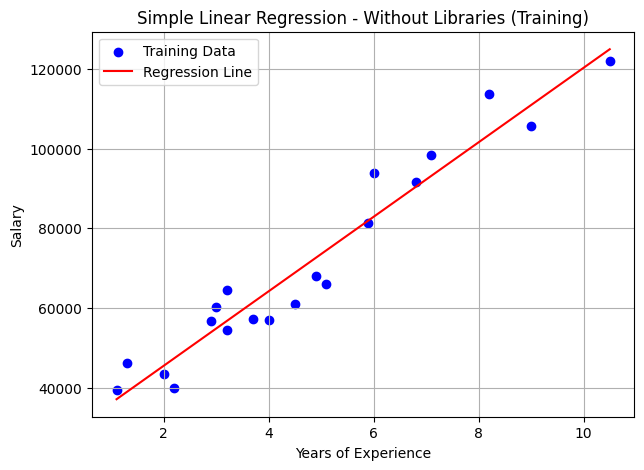

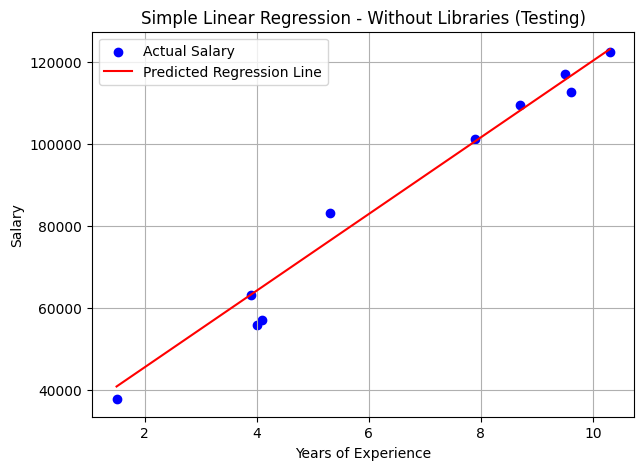

In [ ]:



print("\n========== Without Libraries ==========")

x_train = X_train[:, 0].tolist()
x_test = X_test[:, 0].tolist()
y_train_list = y_train.tolist()
y_test_list = y_test.tolist()

n = len(x_train)

mean_x = sum(x_train) / n
mean_y = sum(y_train_list) / n


numerator = sum(
    (x_train[i] - mean_x) * (y_train_list[i] - mean_y)
    for i in range(n)
)

denominator = sum(
    (x_train[i] - mean_x) ** 2
    for i in range(n)
)

b1 = numerator / denominator


b0 = mean_y - b1 * mean_x

print("Slope:", b1)
print("Intercept:", b0)

y_train_manual = [b0 + b1 * xi for xi in x_train]
y_test_manual = [b0 + b1 * xi for xi in x_test]

def calculate_mse(actual, predicted):
    return sum(
        (actual[i] - predicted[i]) ** 2
        for i in range(len(actual))
    ) / len(actual)

def calculate_mae(actual, predicted):
    return sum(
        abs(actual[i] - predicted[i])
        for i in range(len(actual))
    ) / len(actual)


def calculate_r2(actual, predicted):
    mean_actual = sum(actual) / len(actual)

    ss_res = sum(
        (actual[i] - predicted[i]) ** 2
        for i in range(len(actual))
    )

    ss_tot = sum(
        (value - mean_actual) ** 2
        for value in actual
    )

    return 1 - (ss_res / ss_tot)


print("\nTraining Results")
print("MSE:", calculate_mse(y_train_list, y_train_manual))
print("MAE:", calculate_mae(y_train_list, y_train_manual))
print("R2 Score:", calculate_r2(y_train_list, y_train_manual))

print("\nTesting Results")
print("MSE:", calculate_mse(y_test_list, y_test_manual))
print("MAE:", calculate_mae(y_test_list, y_test_manual))
print("R2 Score:", calculate_r2(y_test_list, y_test_manual))


plt.figure(figsize=(7, 5))
plt.scatter(x_train, y_train_list, color='blue', label='Training Data')

train_sorted = sorted(zip(x_train, y_train_manual))
sx, sy = zip(*train_sorted)

plt.plot(sx, sy, color='red', label='Regression Line')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Simple Linear Regression - Without Libraries (Training)')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(x_test, y_test_list, color='blue', label='Actual Salary')

test_sorted = sorted(zip(x_test, y_test_manual))
sx, sy = zip(*test_sorted)

plt.plot(sx, sy, color='red', label='Predicted Regression Line')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Simple Linear Regression - Without Libraries (Testing)')
plt.legend()
plt.grid(True)
plt.show()

**With ML Library**

Uses Scikit-learn LinearRegression().

Uses fit() to train the model.

Uses predict() to predict values.

Uses built-in functions to calculate MSE, MAE and R².

Requires less code and is easy to implement.

**Without ML Library**

Calculates slope and intercept using formulas.

Uses the regression equation to predict values.

Calculates MSE, MAE and R² manually.

Requires more code and mathematical understanding.

Helps understand the working of the algorithm.

# Multiple Linear Regression

First 5 rows of dataset:
   Unnamed: 0     TV  Radio  Newspaper  Sales
0           1  230.1   37.8       69.2   22.1
1           2   44.5   39.3       45.1   10.4
2           3   17.2   45.9       69.3    9.3
3           4  151.5   41.3       58.5   18.5
4           5  180.8   10.8       58.4   12.9

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB

========== WITH LIBRARIES ==========
Coefficients: [0.0443459  0.19660591 0.00262562]
Intercept: 2.903764504319202

Training Results
MSE: 2.544737086192998
MAE: 1.2693282242320603
R2 Score: 0.906752360867692

Testing Results
MSE: 3.386

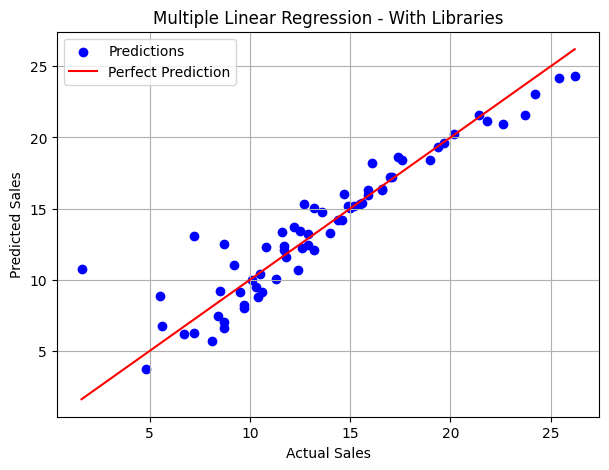

In [ ]:
dataset = pd.read_csv('/content/drive/My Drive/AIML Assignment/Advertising.csv')

print("First 5 rows of dataset:")
print(dataset.head())

print("\nDataset Information:")
dataset.info()


X = dataset[['TV', 'Radio', 'Newspaper']].values
y = dataset['Sales'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=1/3, random_state=0
)


print("\n========== WITH LIBRARIES ==========")

regressor = LinearRegression()
regressor.fit(X_train, y_train)

y_train_pred = regressor.predict(X_train)
y_test_pred = regressor.predict(X_test)

# Model parameters
print("Coefficients:", regressor.coef_)
print("Intercept:", regressor.intercept_)

# Training evaluation
print("\nTraining Results")
print("MSE:", mean_squared_error(y_train, y_train_pred))
print("MAE:", mean_absolute_error(y_train, y_train_pred))
print("R2 Score:", r2_score(y_train, y_train_pred))

# Testing evaluation
print("\nTesting Results")
print("MSE:", mean_squared_error(y_test, y_test_pred))
print("MAE:", mean_absolute_error(y_test, y_test_pred))
print("R2 Score:", r2_score(y_test, y_test_pred))

# Actual vs predicted plot
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_test_pred, color='blue', label='Predictions')

low = min(y_test.min(), y_test_pred.min())
high = max(y_test.max(), y_test_pred.max())

plt.plot([low, high], [low, high], color='red',
         label='Perfect Prediction')

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Multiple Linear Regression - With Libraries')
plt.legend()
plt.grid(True)
plt.show()




========== WITHOUT ML LIBRARIES ==========
Intercept: 2.9037645043192115
Coefficients: [0.044345897197471576, 0.1966059115260808, 0.002625617486140178]

Training Results
MSE: 2.5447370861929994
MAE: 1.269328224232061
R2 Score: 0.9067523608676918

Testing Results
MSE: 3.386478605495977
MAE: 1.1855503777750753
R2 Score: 0.8710873114733415


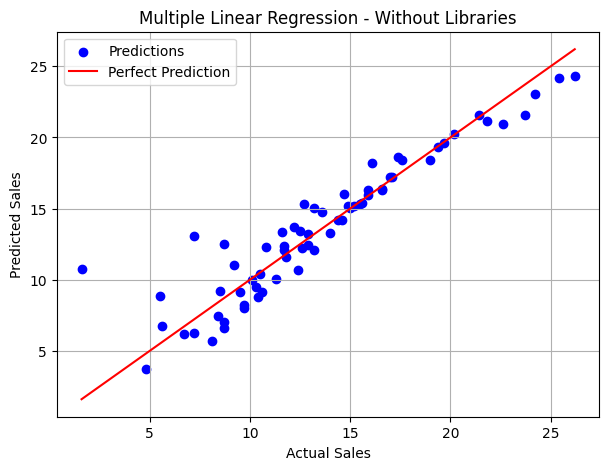

In [ ]:
# MULTIPLE LINEAR REGRESSION WITHOUT ML LIBRARIES

print("\n========== WITHOUT ML LIBRARIES ==========")

x_train = X_train.tolist()
x_test = X_test.tolist()
y_train_list = y_train.tolist()
y_test_list = y_test.tolist()

# Add intercept column (1) to each row
X_train_manual = [[1] + row for row in x_train]
X_test_manual = [[1] + row for row in x_test]

# Gaussian elimination to solve linear equations
def solve(A, b):
    n = len(b)
    M = [A[i][:] + [b[i]] for i in range(n)]

    for i in range(n):
        # Partial pivoting
        pivot = max(range(i, n), key=lambda r: abs(M[r][i]))
        M[i], M[pivot] = M[pivot], M[i]

        if abs(M[i][i]) < 1e-12:
            raise ValueError("Singular matrix")

        # Normalize pivot row
        divisor = M[i][i]
        M[i] = [v / divisor for v in M[i]]

        # Eliminate other rows
        for j in range(n):
            if j != i:
                factor = M[j][i]
                M[j] = [
                    M[j][k] - factor * M[i][k]
                    for k in range(n + 1)
                ]

    return [M[i][-1] for i in range(n)]


# Normal equation: (X'X)b = X'y
p = len(X_train_manual[0])
n = len(X_train_manual)

XtX = [
    [
        sum(row[i] * row[j] for row in X_train_manual)
        for j in range(p)
    ]
    for i in range(p)
]

Xty = [
    sum(X_train_manual[k][i] * y_train_list[k] for k in range(n))
    for i in range(p)
]

# Calculate coefficients
b = solve(XtX, Xty)

print("Intercept:", b[0])
print("Coefficients:", b[1:])

# Prediction function
def predict(X, coefficients):
    return [
        sum(row[j] * coefficients[j] for j in range(len(coefficients)))
        for row in X
    ]

# Predictions
y_train_manual = predict(X_train_manual, b)
y_test_manual = predict(X_test_manual, b)

# Manual MSE
def calculate_mse(actual, predicted):
    return sum(
        (actual[i] - predicted[i]) ** 2
        for i in range(len(actual))
    ) / len(actual)

# Manual MAE
def calculate_mae(actual, predicted):
    return sum(
        abs(actual[i] - predicted[i])
        for i in range(len(actual))
    ) / len(actual)

# Manual R2 Score
def calculate_r2(actual, predicted):
    mean_y = sum(actual) / len(actual)

    ss_res = sum(
        (actual[i] - predicted[i]) ** 2
        for i in range(len(actual))
    )

    ss_tot = sum(
        (value - mean_y) ** 2 for value in actual
    )

    return 1 - (ss_res / ss_tot)


print("\nTraining Results")
print("MSE:", calculate_mse(y_train_list, y_train_manual))
print("MAE:", calculate_mae(y_train_list, y_train_manual))
print("R2 Score:", calculate_r2(y_train_list, y_train_manual))


print("\nTesting Results")
print("MSE:", calculate_mse(y_test_list, y_test_manual))
print("MAE:", calculate_mae(y_test_list, y_test_manual))
print("R2 Score:", calculate_r2(y_test_list, y_test_manual))

plt.figure(figsize=(7, 5))
plt.scatter(y_test_list, y_test_manual,
            color='blue', label='Predictions')

low = min(min(y_test_list), min(y_test_manual))
high = max(max(y_test_list), max(y_test_manual))

plt.plot([low, high], [low, high], color='red',
         label='Perfect Prediction')

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Multiple Linear Regression - Without Libraries')
plt.legend()
plt.grid(True)
plt.show()

# Polynomial Regression


Coefficients: [ 0.00000000e+00  7.41827285e-02 -9.35514348e-05]
Intercept: 5.897330556086377

Training Results
MSE: 11.239401925500397
MAE: 2.734243951484124
R2 Score: 0.5881508936626771

Testing Results
MSE: 8.587097150502562
MAE: 2.2664572878562543
R2 Score: 0.6731159681580903


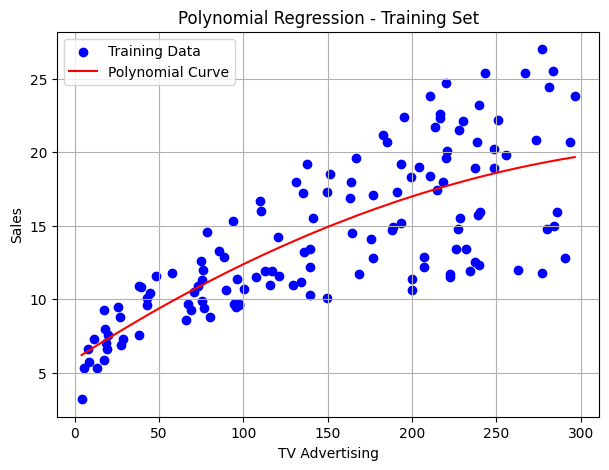

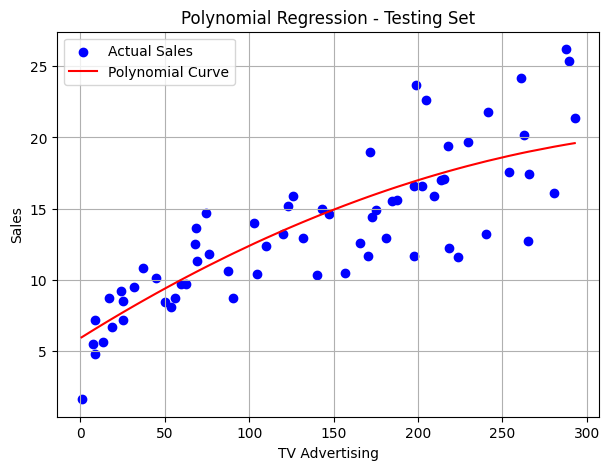

In [ ]:
X = dataset[['TV']].values
y = dataset['Sales'].values

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=1/3, random_state=0
)

# Create polynomial features
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Train model
regressor = LinearRegression()
regressor.fit(X_train_poly, y_train)

# Predictions
y_train_pred = regressor.predict(X_train_poly)
y_test_pred = regressor.predict(X_test_poly)

# Model parameters
print("\nCoefficients:", regressor.coef_)
print("Intercept:", regressor.intercept_)

# Training evaluation
print("\nTraining Results")
print("MSE:", mean_squared_error(y_train, y_train_pred))
print("MAE:", mean_absolute_error(y_train, y_train_pred))
print("R2 Score:", r2_score(y_train, y_train_pred))

# Testing evaluation
print("\nTesting Results")
print("MSE:", mean_squared_error(y_test, y_test_pred))
print("MAE:", mean_absolute_error(y_test, y_test_pred))
print("R2 Score:", r2_score(y_test, y_test_pred))

# Plot training data and polynomial curve
X_curve = pd.DataFrame({
    'TV': sorted(X_train[:, 0])
}).values

y_curve = regressor.predict(poly.transform(X_curve))

plt.figure(figsize=(7, 5))
plt.scatter(X_train, y_train, color='blue', label='Training Data')
plt.plot(X_curve, y_curve, color='red', label='Polynomial Curve')

plt.xlabel('TV Advertising')
plt.ylabel('Sales')
plt.title('Polynomial Regression - Training Set')
plt.legend()
plt.grid(True)
plt.show()

# Plot testing data and polynomial curve
X_curve_test = pd.DataFrame({
    'TV': sorted(X_test[:, 0])
}).values

y_curve_test = regressor.predict(poly.transform(X_curve_test))

plt.figure(figsize=(7, 5))
plt.scatter(X_test, y_test, color='blue', label='Actual Sales')
plt.plot(X_curve_test, y_curve_test, color='red',
         label='Polynomial Curve')

plt.xlabel('TV Advertising')
plt.ylabel('Sales')
plt.title('Polynomial Regression - Testing Set')
plt.legend()
plt.grid(True)
plt.show()

First 5 rows of dataset:
   Unnamed: 0     TV  Radio  Newspaper  Sales
0           1  230.1   37.8       69.2   22.1
1           2   44.5   39.3       45.1   10.4
2           3   17.2   45.9       69.3    9.3
3           4  151.5   41.3       58.5   18.5
4           5  180.8   10.8       58.4   12.9

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB

Training samples: 133
Testing samples: 67

========== GRADIENT DESCENT MODEL ==========
Learning Rate: 0.01
Epochs: 10000
Final Training Loss: 2.544737086192999

Intercept (standardized features): 14.285714285714242
Standardized Coeffi

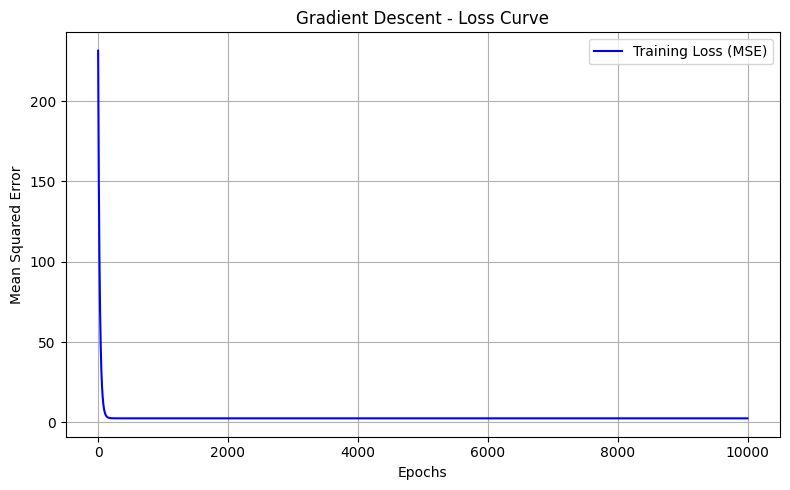

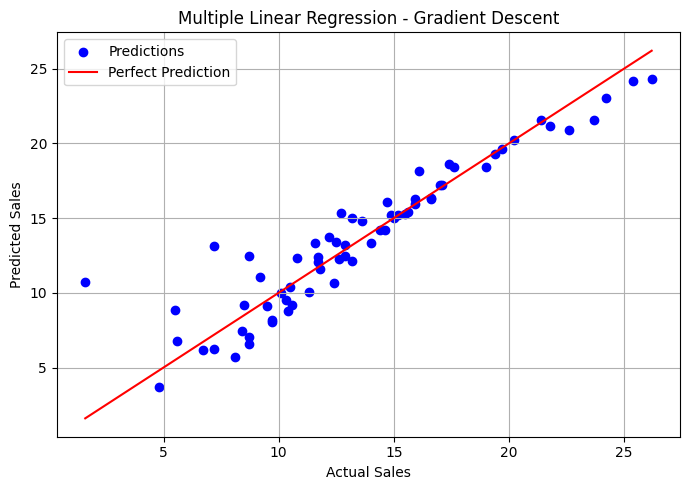

In [ ]:
dataset = pd.read_csv(
    '/content/drive/My Drive/AIML Assignment/Advertising.csv'
)

print("First 5 rows of dataset:")
print(dataset.head())

print("\nDataset Information:")
dataset.info()




X = dataset[['TV', 'Radio', 'Newspaper']].values.astype(float)
y = dataset['Sales'].values.astype(float)



X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=1/3, random_state=0
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))




# Calculate mean and standard deviation using training data only
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)

# Avoid division by zero
X_std[X_std == 0] = 1

X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

# Add intercept column (bias)
X_train_bias = np.c_[
    np.ones(len(X_train_scaled)), X_train_scaled
]

X_test_bias = np.c_[
    np.ones(len(X_test_scaled)), X_test_scaled
]


# ------------------------------------------------------------
# 5. INITIALIZE GRADIENT DESCENT PARAMETERS
# ------------------------------------------------------------

n_samples = len(X_train_bias)
n_features = X_train_bias.shape[1]

# Parameters: [intercept, TV coefficient,
#              Radio coefficient, Newspaper coefficient]
theta = np.zeros(n_features)

learning_rate = 0.01
epochs = 10000

loss_history = []


# ------------------------------------------------------------
# 6. TRAIN MODEL USING BATCH GRADIENT DESCENT
# ------------------------------------------------------------

for epoch in range(epochs):

    # Calculate predictions
    y_train_pred = X_train_bias @ theta

    # Calculate errors
    errors = y_train_pred - y_train

    # Calculate Mean Squared Error loss
    loss = np.mean(errors ** 2)
    loss_history.append(loss)

    # Calculate gradients of MSE
    gradients = (2 / n_samples) * (
        X_train_bias.T @ errors
    )

    # Update parameters
    theta = theta - learning_rate * gradients


# Final training predictions after the last update
y_train_pred = X_train_bias @ theta
y_test_pred = X_test_bias @ theta

print("\n========== GRADIENT DESCENT MODEL ==========")
print("Learning Rate:", learning_rate)
print("Epochs:", epochs)
print("Final Training Loss:", loss_history[-1])




# Coefficients in standardized feature space
print("\nIntercept (standardized features):", theta[0])
print("Standardized Coefficients:", theta[1:])

# Convert coefficients to original feature units
original_coef = theta[1:] / X_std

original_intercept = theta[0] - np.sum(
    original_coef * X_mean
)

print("\nIntercept (original units):", original_intercept)
print("TV Coefficient:", original_coef[0])
print("Radio Coefficient:", original_coef[1])
print("Newspaper Coefficient:", original_coef[2])

print("\nRegression Equation:")
print(
    f"Sales = {original_intercept:.4f}"
    f" + ({original_coef[0]:.4f} * TV)"
    f" + ({original_coef[1]:.4f} * Radio)"
    f" + ({original_coef[2]:.4f} * Newspaper)"
)


# ------------------------------------------------------------
# 8. EVALUATION METRICS
# ------------------------------------------------------------

print("\n========== TRAINING RESULTS ==========")

print("MSE:", mean_squared_error(y_train, y_train_pred))
print("MAE:", mean_absolute_error(y_train, y_train_pred))
print("R2 Score:", r2_score(y_train, y_train_pred))


print("\n========== TESTING RESULTS ==========")

print("MSE:", mean_squared_error(y_test, y_test_pred))
print("MAE:", mean_absolute_error(y_test, y_test_pred))
print("R2 Score:", r2_score(y_test, y_test_pred))


# ------------------------------------------------------------
# 9. LOSS CURVE
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    loss_history,
    color='blue',
    label='Training Loss (MSE)'
)

plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error')
plt.title('Gradient Descent - Loss Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. ACTUAL VS PREDICTED SALES PLOT
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test, y_test_pred,
    color='blue', label='Predictions'
)

low = min(y_test.min(), y_test_pred.min())
high = max(y_test.max(), y_test_pred.max())

plt.plot(
    [low, high], [low, high],
    color='red', label='Perfect Prediction'
)

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Multiple Linear Regression - Gradient Descent')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()